# 9b. Sea ice: figures

Everything here is drawn from what notebook 09a saved, so nothing slow runs. 09a explains each step and has a quick look at each. **Which results** sets the folder the results are opened from.

Every map figure is built the same way, with `extant/plots/antarctica.py`: `map_figure_size` gives the figure's size and `map_axes` its maps and colour bars; then each layer is drawn on those axes by its own call (`heatmaps_of_antarctica` for a field, `ice_edges` for an ice edge), and the rows and columns are labelled. A row of a different kind is a slice of the same axes (`axes[2]`) with its own calls.

## Setup

In [ ]:
import sys
sys.path[:0] = ['..']   # this repository: the extant package and plotting_modules

import logging
import warnings
from pathlib import Path

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.colors import ListedColormap

from extant import sea_ice
from extant.datatree import tree_to_dataset
from extant.logger import setup_logging
from extant.plots import antarctica, era5_evaluation as pe, forced_response as fr, paper_panels, sea_ice as sip

logger = setup_logging('extant', logging.INFO)
xr.set_options(display_expand_attrs=False, display_expand_data=False)
#(t): zarr warns that parts of the stores (the text coordinates, the consolidated metadata) aren't in the Zarr 3
#(t): standard yet; harmless here
warnings.filterwarnings('ignore', message='.*currently not part in the Zarr format 3 specification', category=UserWarning)

In [2]:
%matplotlib inline

## Settings

In [ ]:
#(t): Where 09a and notebook 03 saved their results: JASMIN's scratch
SCRATCH_DIR = Path('/work/scratch-pw4/aborow/ExtAnt')

In [3]:
#(t): The experiments compared with hist-nat, in the order of every figure, and the seasons, the columns of every map
EXPERIMENTS = ['hist-GHG', 'hist-aer', 'hist-totalO3', 'historical']
SEASONS = ['DJF', 'MAM', 'JJA', 'SON']

#(t): The model and experiment of the one-model figures
MODEL = 'CanESM5'
EXPERIMENT = 'hist-GHG'

#(t): As in 09a: the final years compared with hist-nat, and the years compared with ERA5
WINDOW = 21
ERA5_YEARS = slice(1979, 2013)

In [ ]:
#(t): As in 09a: the concentration (%) from which a cell counts as ice, and the Earth's mean radius (km)
THRESHOLD = 15.0
EARTH_RADIUS = 6371.0

### Colour scales

One per quantity, so a quantity looks the same in every figure. Each is the colour settings of `antarctica.heatmaps_of_antarctica`: the edges of the colour steps (`levels`), the colours, which ends get a colour of their own for values beyond the levels (`extend`), the colour bar's ticks and label; a figure passes one as `**concentration_colours`. A difference in concentration is blue where there is more ice and red where there is less, so that ice lost reads like warming on the temperature maps.

In [ ]:
#(t): The concentration (%), light to dark blue
concentration_colours = dict(levels=np.arange(0, 101, 10), cmap='Blues', extend='neither',
                             label='Sea-ice concentration (%)')

#(t): A difference in concentration (%): blue where there is more ice, red where there is less
concentration_change_colours = dict(levels=np.arange(-55, 56, 10), cmap='RdBu', extend='both',
                                    ticks=np.arange(-50, 51, 10), label='Difference in sea-ice concentration (%)')

#(t): The correlation of the sea ice and the temperature
correlation_colours = dict(levels=np.round(np.arange(-1, 1.01, 0.2), 1), cmap='PuOr_r', extend='neither',
                           label='Correlation of sea ice and temperature')

#(t): The zones of 09a, section 7: one colour each, in the order of their numbers (sea_ice.ZONES)
zone_colours = dict(levels=np.arange(-0.5, len(sea_ice.ZONES)), extend='neither', ticks=np.arange(len(sea_ice.ZONES)),
                    cmap=ListedColormap(['#f4f3ef', '#2c7fb8', '#e6550d', '#31a354', '#bdbdbd']), label='Zone')

#(t): The temperature's mean change and change in width, on notebook 04's scales (fr.colour_scales; ranges in fr.RANGES)
tas_scales = fr.colour_scales('tas')
mean_change_colours = dict(levels=tas_scales.change.levels, cmap=tas_scales.change.cmap, extend='both',
                           label=tas_scales.change.label)
width_change_colours = dict(levels=tas_scales.spread_change.levels, cmap=tas_scales.spread_change.cmap, extend='both',
                            label=tas_scales.spread_change.label)

#(t): ERA5's ice edge, orange, apart from the models' black
ERA5_COLOR = '#d95f02'

## Which results

Run **one** of the next two sections: each sets the folders the results are opened from.

### Sample data

In [ ]:
#(t): The sample's results: 09a's, and notebook 03's temperature results
RESULTS_DIR = SCRATCH_DIR / 'results' / 'siconc' / 'sample'
TAS_RESULTS_DIR = SCRATCH_DIR / 'results' / 'tas' / 'sample'

### Full data

In [ ]:
#(t): The full data's results: 09a's, and notebook 03's temperature results
RESULTS_DIR = SCRATCH_DIR / 'results' / 'siconc' / 'full'
TAS_RESULTS_DIR = SCRATCH_DIR / 'results' / 'tas' / 'full'

## Open the results

First what 09a saved in `RESULTS_DIR`, then each result opened.

In [ ]:
#(t): What 09a saved in RESULTS_DIR
RESULTS_DIR, sorted(path.name for path in RESULTS_DIR.glob('*.zarr'))

In [ ]:
#(t): 09a's section 1 example: one field on the model's own grid and on the 2.5° grid. It is the sample whichever data
#(t): is used, so 09a saves it outside the run folders
regrid_example_path = SCRATCH_DIR / 'results' / 'siconc' / 'regrid_example.zarr'
regrid_example_ds = xr.open_zarr(regrid_example_path).load()
regrid_example_ds

In [ ]:
#(t): Each member's seasonal extent and its model's continent (km²), /<model>/<experiment>
ice_extents_tree = xr.open_datatree(RESULTS_DIR / 'extent.zarr', engine='zarr').load()
ice_extents_tree

In [ ]:
#(t): The ensemble-mean concentration over each experiment's final WINDOW years (%)
ice_climatology_da = xr.open_zarr(RESULTS_DIR / 'climatology.zarr')['siconc'].load()
ice_climatology_da

In [ ]:
#(t): Each cell's ocean (km²), every model and experiment
ocean_area_da = xr.open_zarr(RESULTS_DIR / 'ocean_area.zarr')['ocean_area'].load()
ocean_area_da

In [ ]:
#(t): Each historical member's seasonal cycle of extent over ERA5_YEARS (million km²), /<model>/historical
historical_cycle_tree = xr.open_datatree(RESULTS_DIR / 'historical_cycle.zarr', engine='zarr').load()
historical_cycle_tree

In [ ]:
#(t): ... and ERA5's
era5_cycle_da = xr.open_zarr(RESULTS_DIR / 'era5_cycle.zarr')['extent'].load()
era5_cycle_da

In [ ]:
#(t): Each model's historical concentration over ERA5_YEARS (%)
historical_climatology_da = xr.open_zarr(RESULTS_DIR / 'historical_climatology.zarr')['siconc'].load()
historical_climatology_da

In [ ]:
#(t): ... and ERA5's
era5_climatology_da = xr.open_zarr(RESULTS_DIR / 'era5_climatology.zarr')['siconc'].load()
era5_climatology_da

In [ ]:
#(t): Each historical member's ice edge over ERA5_YEARS, as an equivalent latitude (degrees), /<model>/historical
historical_member_edges_tree = xr.open_datatree(RESULTS_DIR / 'historical_member_edges.zarr', engine='zarr').load()
historical_member_edges_tree

In [ ]:
#(t): ... and ERA5's
era5_edge_da = xr.open_zarr(RESULTS_DIR / 'era5_edge.zarr')['edge_latitude'].load()
era5_edge_da

In [ ]:
#(t): Each experiment's change in concentration against hist-nat (%)
ice_change_da = xr.open_zarr(RESULTS_DIR / 'ice_change.zarr')['siconc'].load()
ice_change_da

In [ ]:
#(t): ... and in extent (million km²) and edge (degrees)
extent_change_ds = xr.open_zarr(RESULTS_DIR / 'extent_change.zarr').load()
extent_change_ds

In [ ]:
#(t): Each cell's zone (the numbers of sea_ice.ZONES)
ice_zones_da = xr.open_zarr(RESULTS_DIR / 'zones.zarr')['zone'].load()
ice_zones_da

In [ ]:
#(t): The temperature changes in each zone, and each zone's area
tas_zone_means_ds = xr.open_zarr(RESULTS_DIR / 'zone_means.zarr').load()
tas_zone_means_ds

In [ ]:
#(t): The temperature changes over hist-nat's ice
ice_region_change_ds = xr.open_zarr(RESULTS_DIR / 'ice_region_change.zarr').load()
ice_region_change_ds

In [ ]:
#(t): Notebook 03's mean change, for the figures of what goes into the zones
mean_change_da = xr.open_zarr(TAS_RESULTS_DIR / 'mean_bootstrap.zarr')['mean_change'].load()
mean_change_da

In [ ]:
#(t): ... and its change in width, Q95 - Q05
width_change_da = xr.open_zarr(TAS_RESULTS_DIR / 'qrange_change.zarr')['qrange_change'].load()
width_change_da

## 1. How to Regrid

09a, section 1, on one month of one sample file.

In [ ]:
#(t): How a field goes onto the 2.5° grid (09a, section 1), close up on sip.REGRID_REGION: a) the field on its own grid,
#(t): one dot per point; b) each 2.5° cell, the area-weighted mean of its points; c) the whole field on the 2.5° grid
native_da, native_lat_da, native_lon_da = (regrid_example_ds['native'], regrid_example_ds['native_lat'],
                                           regrid_example_ds['native_lon'])
on_grid_da = regrid_example_ds['on_grid']

fig = plt.figure(figsize=(14.0, 5.6))
#(c): The two close-ups (a, b) and the map (c), side by side
grid = fig.add_gridspec(1, 3, width_ratios=(1.25, 1.25, 1), left=0.05, right=0.98, top=0.86, bottom=0.08, wspace=0.3)
ax_a = fig.add_subplot(grid[0])
ax_b = fig.add_subplot(grid[1])
c_axes, c_cbar_axes = antarctica.map_axes(fig, n_rows=1, n_cols=1, n_colorbars=1, subplot_spec=grid[2])

#(c): a) and b), on one colour bar under them both
dots = sip.plot_native_points(native_da, native_lat_da, native_lon_da, on_grid_da, ax=ax_a)
sip.plot_grid_cells(native_da, native_lat_da, native_lon_da, on_grid_da, ax=ax_b)
ax_a.set_title('a) The field on its own grid: one dot per point', loc='left')
ax_b.set_title('b) Each 2.5° cell: the area-weighted mean of its points', loc='left')
fig.colorbar(dots, ax=[ax_a, ax_b], orientation='horizontal', shrink=0.6, pad=0.15, label='Concentration (%); grey: land')

#(c): c) the whole field, with the close-ups' region outlined
antarctica.heatmaps_of_antarctica(on_grid_da, None, None, axes=c_axes, cax=c_cbar_axes[0], levels=sip.REGRID_LEVELS,
                                  cmap='Blues', extend='neither', label='Concentration (%)')
(south, north), (west, east) = sip.REGRID_REGION
box_lon_arr = np.r_[np.linspace(west, east, 30), np.full(30, east), np.linspace(east, west, 30), np.full(30, west)]
box_lat_arr = np.r_[np.full(30, south), np.linspace(south, north, 30), np.full(30, north), np.linspace(north, south, 30)]
c_axes[0, 0].plot(box_lon_arr, box_lat_arr, color=pe.OUTSIDE_COLOR, lw=1.4, transform=ccrs.PlateCarree())
c_axes[0, 0].set_title('c) The whole field on the 2.5° grid', loc='left')
fig.suptitle(f'How a field goes onto the 2.5° grid: {MODEL}, historical, September 2013', fontsize=11,
             fontweight='bold', x=0.01, ha='left');

## 2. Extent and Ice Edge

**The edge as an equivalent latitude**, on `MODEL`'s hist-nat ensemble mean in JJA: the concentration and its 15% line; the cells that count (ice, and the continent), with the circle that encloses the same area; and the cap's area read back as a latitude. As in 09a, section 4.

In [19]:
#(t): The field, and its cells' ocean
example_field_da = ice_climatology_da.sel(model=MODEL, experiment='hist-nat', season='JJA')
example_ocean_area_da = ocean_area_da.sel(model=MODEL, experiment='hist-nat')

In [ ]:
#(t): The cells that count as ice (at least THRESHOLD %), and the continent: the land (no concentration) south of 60°S
example_ice_cells_da = example_field_da >= THRESHOLD
example_continent_cells_da = example_field_da.isnull() & (example_field_da['lat'] <= -60)

In [ ]:
#(t): The extent: the ocean of the ice cells (km²)
example_extent = float(example_ocean_area_da.where(example_ice_cells_da, 0).sum())
example_extent

In [ ]:
#(t): The continent's area (km²), as 09a saved it with MODEL's hist-nat extent
example_continent_area = float(ice_extents_tree[MODEL]['hist-nat']['continent_area'])
example_continent_area

In [ ]:
#(t): The edge: the latitude whose polar cap holds the extent and the continent, arcsin(area / 2πR² − 1) (degrees)
example_edge_latitude = float(np.rad2deg(np.arcsin((example_extent + example_continent_area)
                                                   / (2 * np.pi * EARTH_RADIUS ** 2) - 1)))
example_edge_latitude

In [ ]:
#(t): How the ice edge becomes a latitude: a) the concentration and its THRESHOLD % contour; b) the cells that count,
#(t): ice and the continent, and the circle of the equivalent latitude, which encloses the same area; c) the area
#(t): south of each latitude, read backwards from that total
fig = plt.figure(figsize=(13.5, 5.6))
#(c): Two maps (a, b), each with a colour bar's row under it, and a plain plot (c)
grid = fig.add_gridspec(1, 3, width_ratios=(1, 1, 1.15), left=0.03, right=0.98, top=0.86, bottom=0.1, wspace=0.25)
a_axes, a_cbar_axes = antarctica.map_axes(fig, n_rows=1, n_cols=1, n_colorbars=1, subplot_spec=grid[0])
b_axes, b_cbar_axes = antarctica.map_axes(fig, n_rows=1, n_cols=1, n_colorbars=1, subplot_spec=grid[1])
ax_c = fig.add_subplot(grid[2])

#(c): a) the concentration, and its contour
antarctica.heatmaps_of_antarctica(example_field_da, None, None, axes=a_axes, cax=a_cbar_axes[0],
                                  levels=np.arange(0, 101, 10), cmap='Blues', extend='neither',
                                  label='Concentration (%)')
antarctica.ice_edges(example_field_da, None, None, axes=a_axes)
a_axes[0, 0].set_title(f'a) Concentration, and its {THRESHOLD:g}% contour', loc='left')

#(c): b) each cell: open water (0), ice (1) or the continent (2); and the circle at the equivalent latitude
example_cells_da = (example_ice_cells_da.astype(int) + 2 * example_continent_cells_da.astype(int)).clip(max=2)
antarctica.heatmaps_of_antarctica(example_cells_da, None, None, axes=b_axes, levels=np.arange(-0.5, 3),
                                  cmap=ListedColormap(sip.CELL_COLORS), extend='neither')
b_axes[0, 0].plot(np.linspace(-180, 180, 361), np.full(361, example_edge_latitude), color=pe.OUTSIDE_COLOR, lw=2,
                  transform=ccrs.PlateCarree())
b_axes[0, 0].set_title(f'b) Ice ≥ {THRESHOLD:g}% plus the continent', loc='left')
#(c): Its legend where a colour bar would go
b_cbar_axes[0].axis('off')
b_cbar_axes[0].legend(handles=[
    plt.Line2D([], [], linestyle='none', marker='s', ms=9, color=sip.CELL_COLORS[1],
               label=f'Ice: {example_extent / 1e6:.1f} million km²'),
    plt.Line2D([], [], linestyle='none', marker='s', ms=9, color=sip.CELL_COLORS[2],
               label=f'Continent: {example_continent_area / 1e6:.1f} million km²'),
    plt.Line2D([], [], color=pe.OUTSIDE_COLOR, lw=2, label=f'Same area, as a cap: {abs(example_edge_latitude):.1f}°S'),
], loc='upper center', frameon=False, fontsize=8)

#(c): c) the area south of each latitude, read backwards
sip.plot_cap_area(example_extent, example_continent_area, example_edge_latitude, ax=ax_c)
ax_c.set_title('c) A(φ) = 2πR²(1 + sin φ), read backwards', loc='left')
fig.suptitle(f'How the ice edge becomes a latitude: {MODEL}, hist-nat, final {WINDOW} years, JJA', fontsize=11,
             fontweight='bold', x=0.01, ha='left');

**Each experiment's extent through time**: the ensemble mean and the members' 5–95%.

In [ ]:
#(t): Each experiment's ensemble-mean extent, every year and season (km²)
ice_extent_mean_tree = ice_extents_tree.mean('member')

In [ ]:
#(t): ... and the members' 5% and 95% (km²)
ice_extent_spread_tree = xr.DataTree.from_dict({node.path: node['extent'].quantile([0.05, 0.95], 'member').to_dataset()
                                                for node in ice_extents_tree.leaves})

In [ ]:
#(t): Every model and experiment side by side, on (model, experiment, year, season)
ice_extent_mean_ds = tree_to_dataset(ice_extent_mean_tree, dims=['model', 'experiment'])
ice_extent_spread_ds = tree_to_dataset(ice_extent_spread_tree, dims=['model', 'experiment'])

In [ ]:
#(t): Together, for the figure: mean, low (5%) and high (95%)
ice_extent_summary_ds = xr.Dataset({'mean': ice_extent_mean_ds['extent'],
                                    'low': ice_extent_spread_ds['extent'].sel(quantile=0.05, drop=True),
                                    'high': ice_extent_spread_ds['extent'].sel(quantile=0.95, drop=True)})
ice_extent_summary_ds

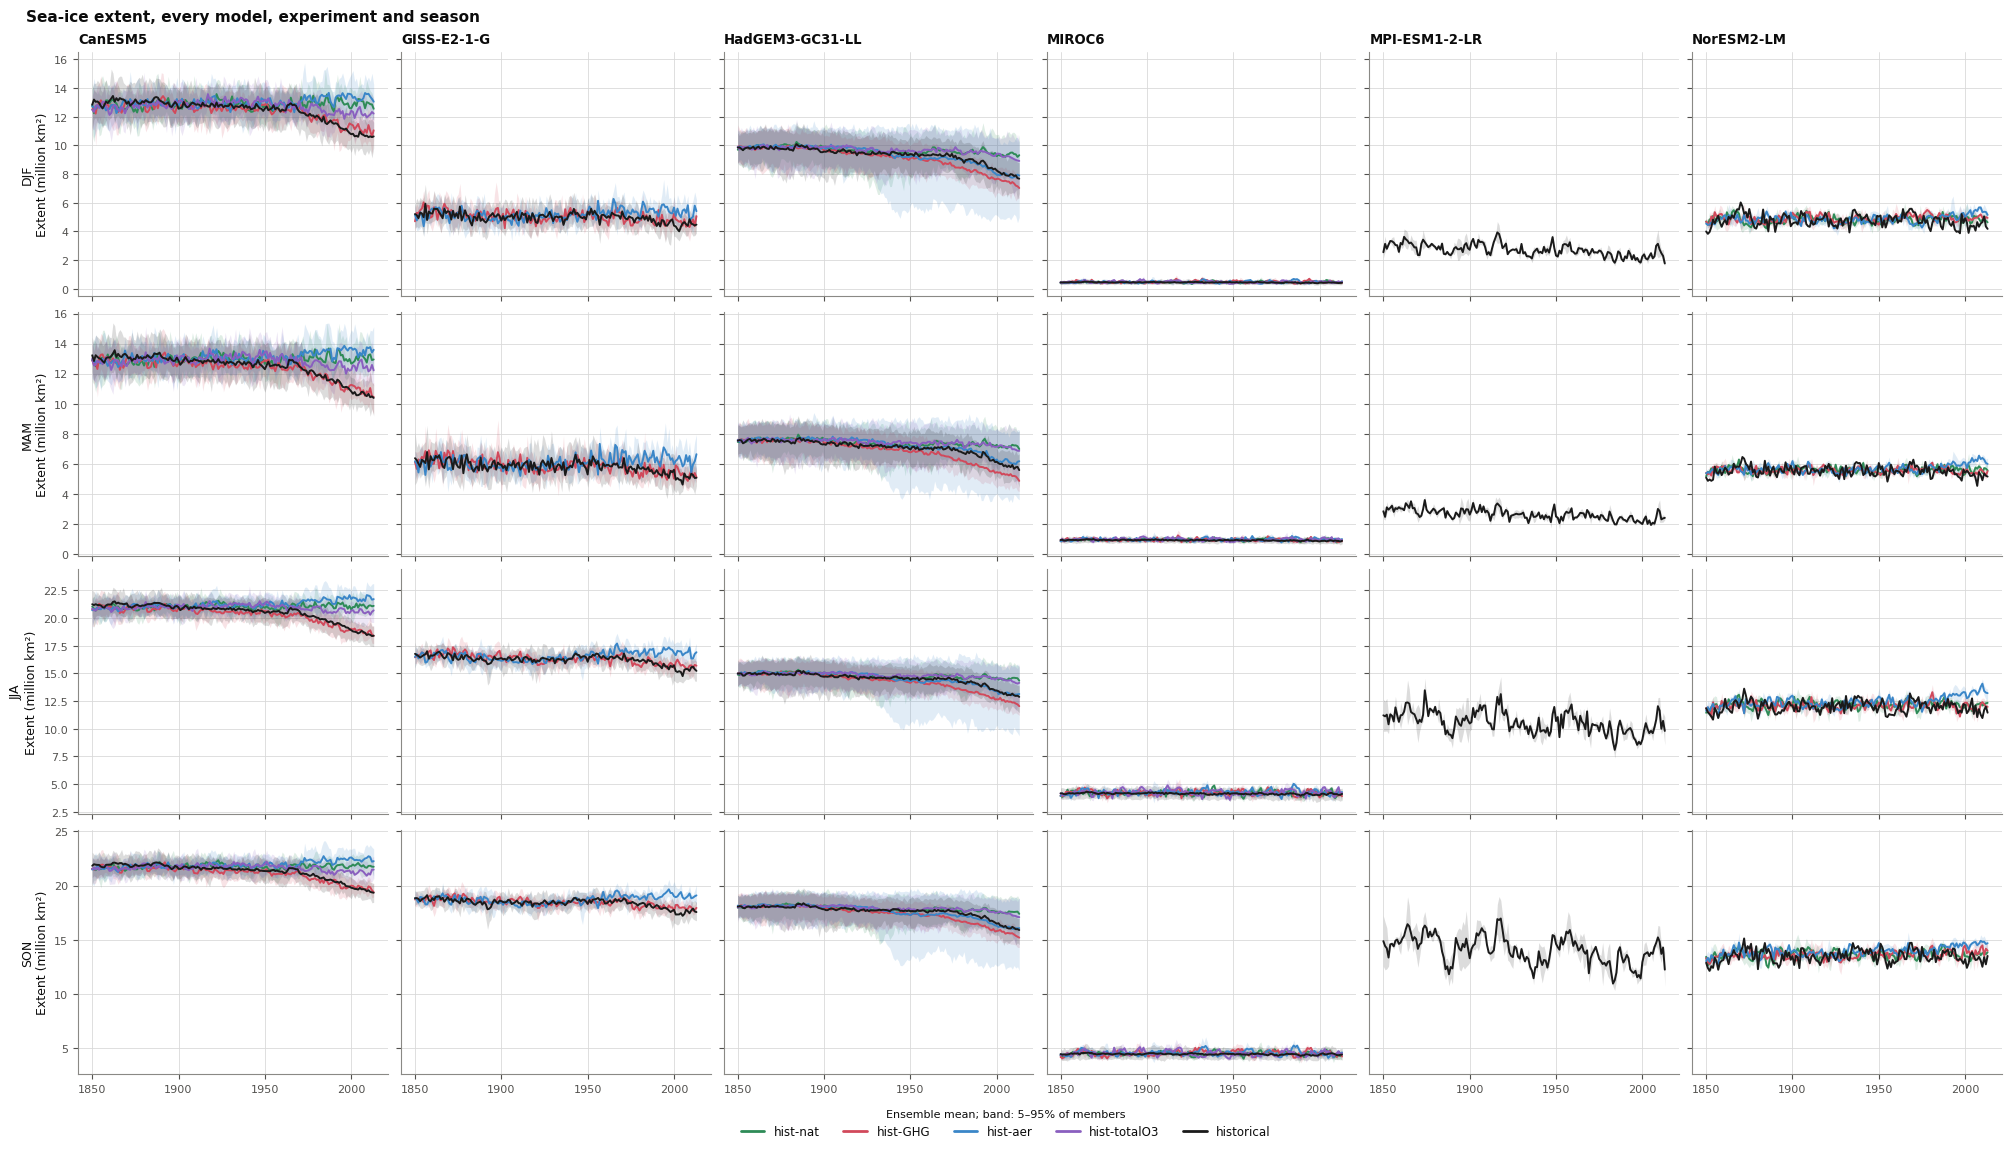

In [23]:
fig, axes = sip.extent_timeseries(ice_extent_summary_ds, seasons=SEASONS,
                                  title='Sea-ice extent, every model, experiment and season')

## 3. Comparison with ERA5

Each model's historical members against ERA5 over `ERA5_YEARS`, counted on the same grid in the same way. The usual CMIP6 picture (Roach et al., 2020): most models have too little ice in summer and a spread of winter extents round the observed one.

### Seasonal cycle

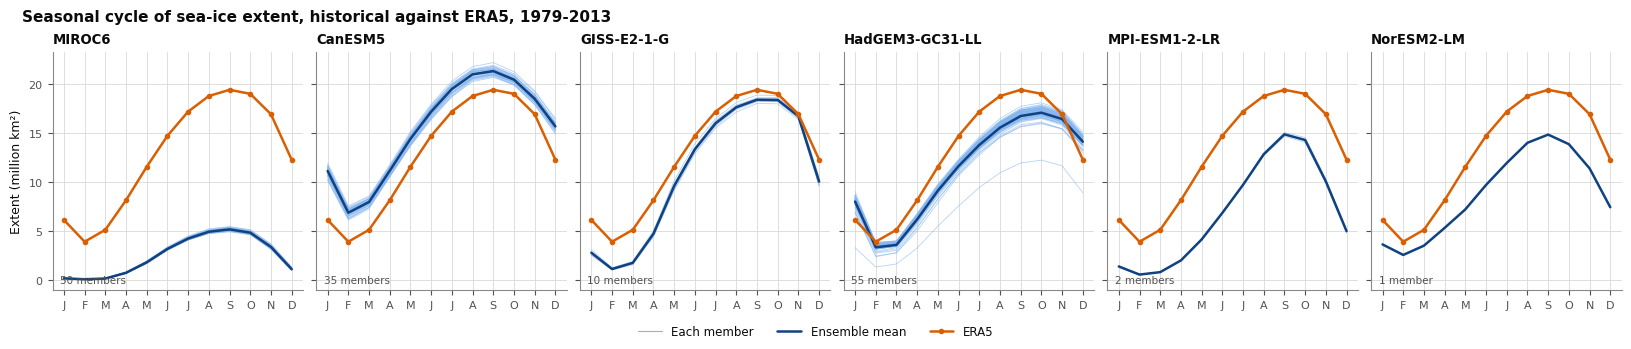

In [24]:
fig, axes = sip.seasonal_cycle(historical_cycle_tree, era5_cycle_da,
                               title=f'Seasonal cycle of sea-ice extent, historical against ERA5, '
                                     f'{ERA5_YEARS.start}-{ERA5_YEARS.stop}')

### Concentration and edge

The historical ensemble-mean concentration minus ERA5's, with both edges: the model's (black) and ERA5's (orange). Blue: the model has more ice.

In [25]:
#(t): The difference
historical_bias_da = historical_climatology_da - era5_climatology_da

In [ ]:
#(t): ERA5's concentration on every model's row, so its edge can be drawn on each (the same on every row)
era5_every_row_da = era5_climatology_da.broadcast_like(historical_climatology_da)

In [ ]:
#(t): Quick look: ERA5's concentration in DJF
era5_climatology_da.sel(season='DJF').plot();

In [ ]:
#(t): Quick look: ERA5's field on the first model's row, in DJF (the same on every row)
era5_every_row_da.sel(season='DJF').isel(model=0).plot();

In [ ]:
#(t): Quick look: every model's historical edge (colours) and ERA5's (black) in DJF, on one map
colors = ['red', 'green', 'blue', 'brown', 'yellow', 'orange']
fig, ax = plt.subplots(subplot_kw=dict(projection=ccrs.SouthPolarStereo()))
antarctica.style_antarctic_ax(ax)
for i, model in enumerate(historical_climatology_da.model.values):
    antarctica.ice_edge(historical_climatology_da.sel(model=model, season='DJF'), ax=ax, color=colors[i])
antarctica.ice_edge(era5_climatology_da.sel(season='DJF'), ax=ax, color='black')
#(c): The legend by hand: the edges are contour lines, which carry no labels
legend_lines = [plt.Line2D([], [], color=colors[i], label=model) for i, model in enumerate(historical_climatology_da.model.values)]
ax.legend(handles=legend_lines + [plt.Line2D([], [], color='black', label='ERA5')], fontsize=7, loc='center left',
          bbox_to_anchor=(1, 0.5));

In [ ]:
#(t): Quick look: ERA5's edge (red) and the last model's, NorESM2-LM (green), in DJF
fig, ax = plt.subplots(subplot_kw=dict(projection=ccrs.SouthPolarStereo()))
antarctica.style_antarctic_ax(ax)
antarctica.ice_edge(era5_climatology_da.sel(season='DJF'), ax=ax, color='red')
antarctica.ice_edge(historical_climatology_da.sel(season='DJF').isel(model=-1), ax=ax, color='green');

In [ ]:
#(t): Every model (rows) and season (columns): the difference, each model's own edge (black) and ERA5's (orange)
n_models = historical_bias_da.sizes['model']
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=n_models, n_cols=len(SEASONS), n_colorbars=1))
axes, cbar_axes = antarctica.map_axes(fig, n_rows=n_models, n_cols=len(SEASONS), n_colorbars=1)

antarctica.heatmaps_of_antarctica(historical_bias_da.sel(season=SEASONS), 'model', 'season', axes=axes,
                                  cax=cbar_axes[0], **concentration_change_colours)
antarctica.ice_edges(historical_climatology_da.sel(season=SEASONS), 'model', 'season', axes=axes)
antarctica.ice_edges(era5_every_row_da.sel(season=SEASONS), 'model', 'season', axes=axes, color=ERA5_COLOR)

antarctica.label_columns(axes, SEASONS)
antarctica.label_rows(axes, historical_bias_da['model'].values)
fig.legend(handles=[plt.Line2D([], [], color='k', label="The model's edge"),
                    plt.Line2D([], [], color=ERA5_COLOR, label="ERA5's edge")], loc='lower right', fontsize=8)
fig.suptitle(f'Sea-ice concentration, historical minus ERA5, {ERA5_YEARS.start}-{ERA5_YEARS.stop}');

### Edge as an equivalent latitude

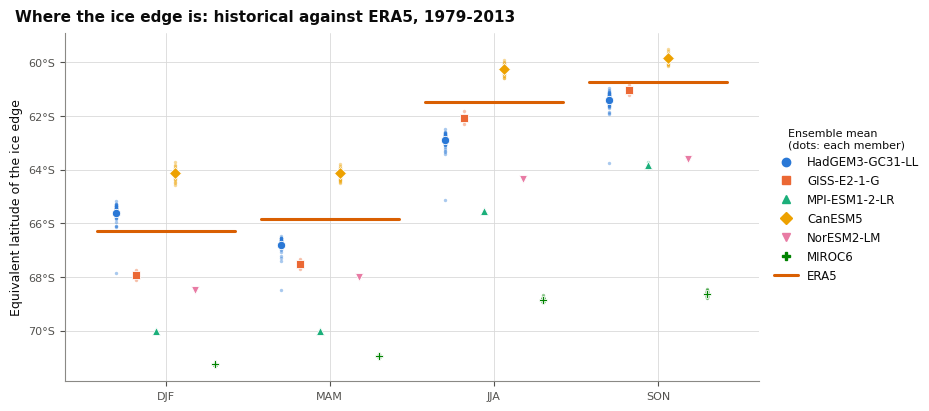

In [28]:
fig, axes = sip.edge_latitudes(historical_member_edges_tree, era5_edge_da.sel(season=SEASONS),
                               title=f'Where the ice edge is: historical against ERA5, {ERA5_YEARS.start}-{ERA5_YEARS.stop}')

### ERA5 among the members

09a, section 6: the extent's mean, variability and trend. A tick: ERA5 inside the members' 5–95%; a cross: outside (and what that means for the model); a dash: too few members to flag anything.

In [ ]:
#(t): ERA5 among each model's members, /<model>/historical, on (statistic, season, member)
era5_extent_test_tree = xr.open_datatree(RESULTS_DIR / 'era5_extent_test.zarr', engine='zarr').load()
era5_extent_test_tree

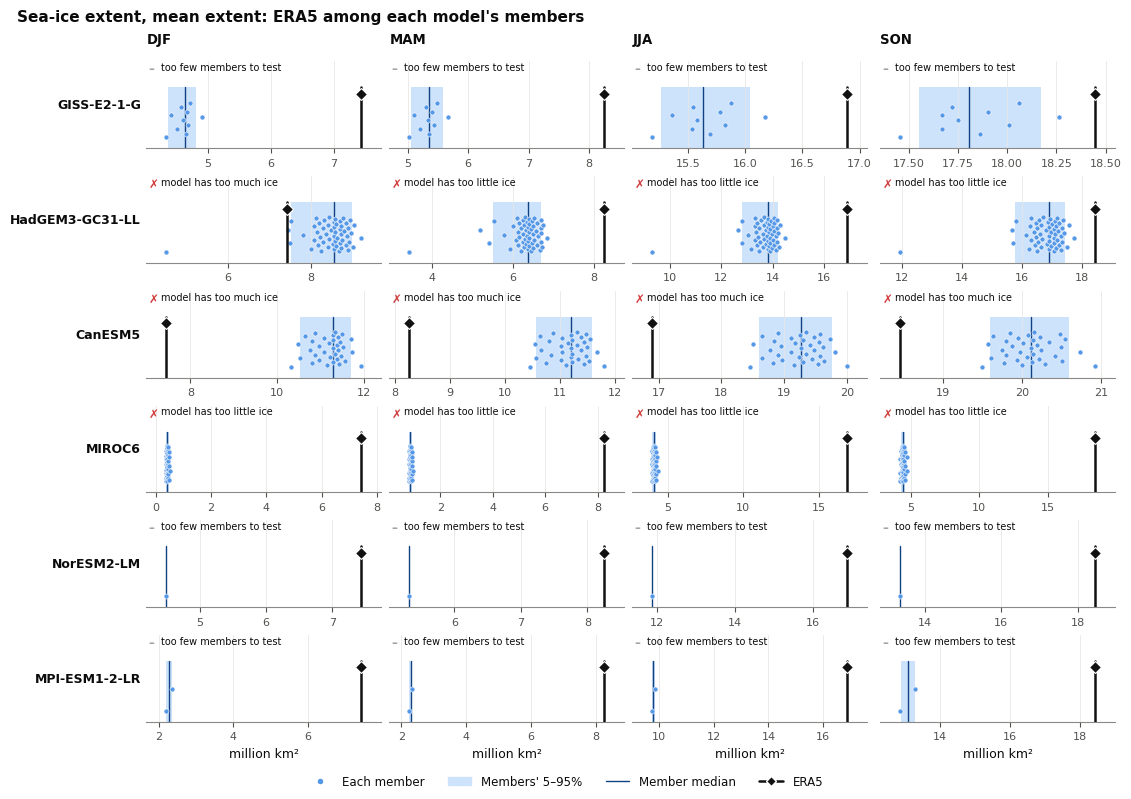

In [30]:
fig, axes = sip.era5_strips(era5_extent_test_tree, 'mean')

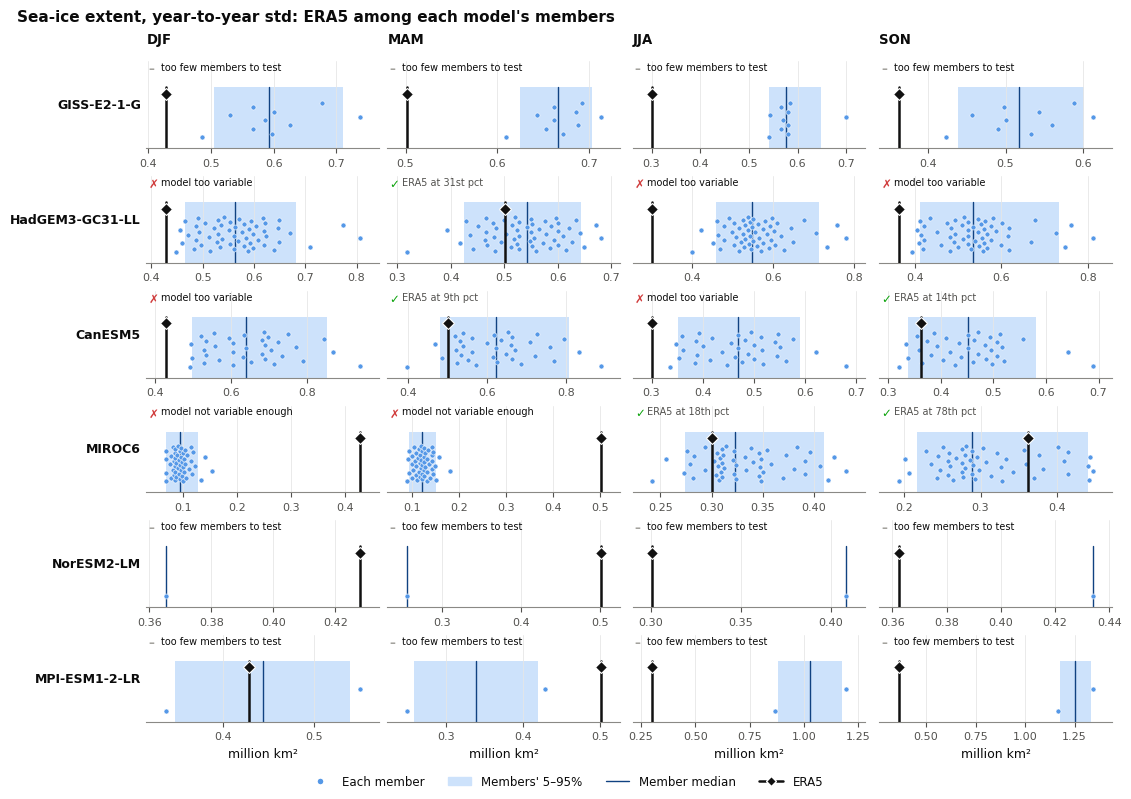

In [31]:
fig, axes = sip.era5_strips(era5_extent_test_tree, 'std')

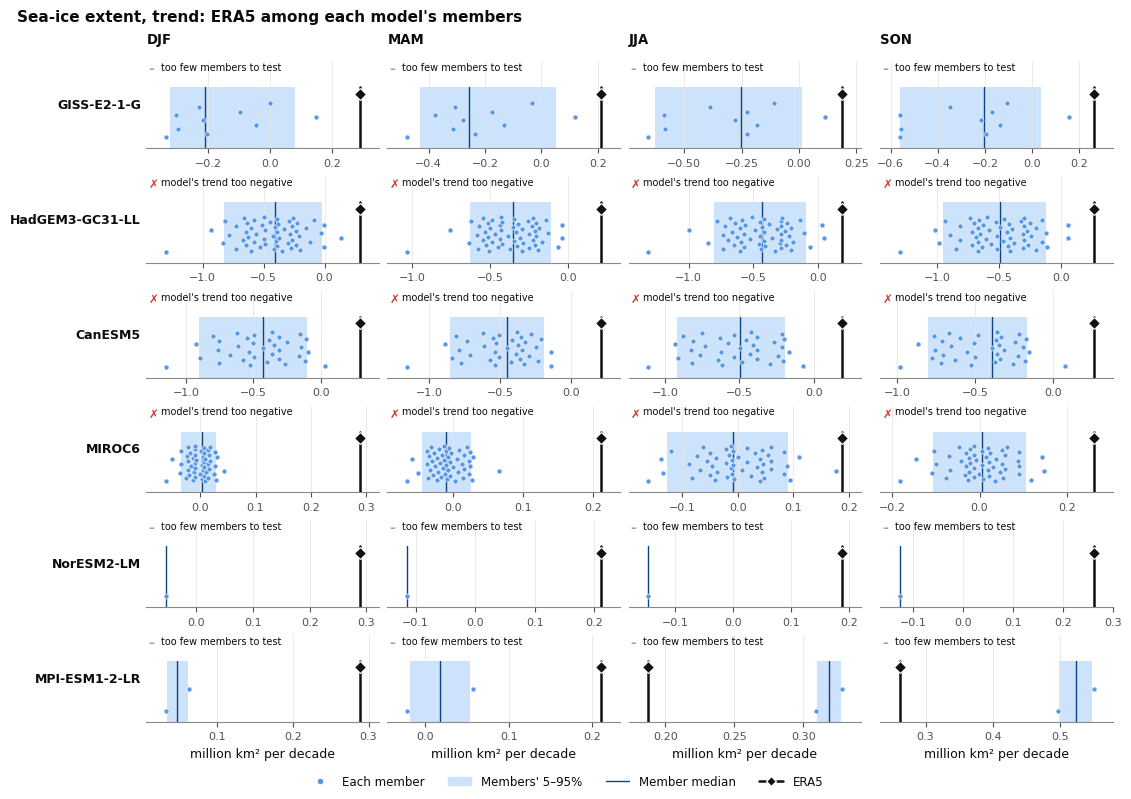

In [32]:
fig, axes = sip.era5_strips(era5_extent_test_tree, 'trend')

In [33]:
#(t): Every model's verdicts, on (model, statistic, season)
era5_extent_verdicts_ds = xr.concat([node.to_dataset()[['percentile', 'verdict', 'testable']]
                                     for node in era5_extent_test_tree.leaves],
                                    dim=xr.Variable('model', [node.parent.name for node in era5_extent_test_tree.leaves]))
era5_extent_verdicts_ds

<xarray.Dataset> Size: 2kB
Dimensions:     (model: 6, statistic: 3, season: 4)
Coordinates:
  * statistic   (statistic) object 24B 'mean' 'std' 'trend'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * model       (model) <U15 360B 'GISS-E2-1-G' ... 'MPI-ESM1-2-LR'
Data variables:
    percentile  (model, statistic, season) float64 576B 100.0 100.0 ... 0.0
    verdict     (model, statistic, season) float64 576B 0.0 0.0 0.0 ... 0.0 0.0
    testable    (model, statistic, season) float64 576B 0.0 0.0 0.0 ... 0.0 0.0

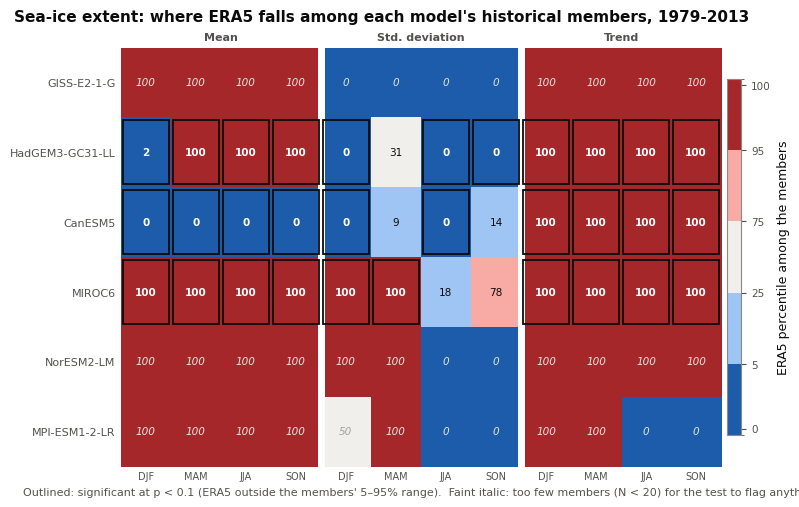

In [34]:
panels = pe.scorecard(era5_extent_verdicts_ds.sel(season=SEASONS),
                      title=f"Sea-ice extent: where ERA5 falls among each model's historical members, "
                            f"{ERA5_YEARS.start}-{ERA5_YEARS.stop}")

## 4. Sea Ice and Temperature Change

### Sea-ice change

Each experiment's ensemble-mean concentration over the final `WINDOW` years minus hist-nat's, with hist-nat's edge (dashed) and the experiment's (solid). Blue: more ice; red: less.

In [ ]:
#(t): MODEL's concentration over the final WINDOW years, every experiment and season
model_ice_da = ice_climatology_da.sel(model=MODEL, season=SEASONS)
model_ice_da

In [ ]:
#(t): What goes in: hist-nat's and EXPERIMENT's concentration, each with its edge (one colour bar), then the change
#(t): with both edges
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=3, n_cols=len(SEASONS), n_colorbars=2))
axes, cbar_axes = antarctica.map_axes(fig, n_rows=3, n_cols=len(SEASONS), n_colorbars=2)

#(c): Rows 1 and 2: hist-nat's and EXPERIMENT's concentration, each with its own edge
antarctica.heatmaps_of_antarctica(model_ice_da.sel(experiment=['hist-nat', EXPERIMENT]), 'experiment', 'season',
                                  axes=axes[:2], cax=cbar_axes[0], **concentration_colours)
antarctica.ice_edges(model_ice_da.sel(experiment='hist-nat'), None, 'season', axes=axes[0], linestyle='dashed')
antarctica.ice_edges(model_ice_da.sel(experiment=EXPERIMENT), None, 'season', axes=axes[1])

#(c): Row 3: the change, with both edges
antarctica.heatmaps_of_antarctica(ice_change_da.sel(model=MODEL, experiment=EXPERIMENT, season=SEASONS), None, 'season',
                                  axes=axes[2], cax=cbar_axes[1], **concentration_change_colours)
antarctica.ice_edges(model_ice_da.sel(experiment='hist-nat'), None, 'season', axes=axes[2], linestyle='dashed')
antarctica.ice_edges(model_ice_da.sel(experiment=EXPERIMENT), None, 'season', axes=axes[2])

antarctica.label_columns(axes, SEASONS)
antarctica.label_rows(axes, [f'hist-nat\nfinal {WINDOW} years', f'{EXPERIMENT}\nfinal {WINDOW} years',
                             f'Change\n{EXPERIMENT} − hist-nat'])
fig.legend(handles=[plt.Line2D([], [], color='k', linestyle='dashed', label="hist-nat's edge"),
                    plt.Line2D([], [], color='k', label=f"{EXPERIMENT}'s edge")], loc='lower right', fontsize=8)
fig.suptitle(f'What goes into the change in sea ice: {MODEL}, {EXPERIMENT}');

In [ ]:
#(t): One model: MODEL's change in every experiment (rows), with hist-nat's edge (dashed) and each experiment's (solid)
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=len(EXPERIMENTS), n_cols=len(SEASONS), n_colorbars=1))
axes, cbar_axes = antarctica.map_axes(fig, n_rows=len(EXPERIMENTS), n_cols=len(SEASONS), n_colorbars=1)

antarctica.heatmaps_of_antarctica(ice_change_da.sel(model=MODEL, experiment=EXPERIMENTS, season=SEASONS), 'experiment',
                                  'season', axes=axes, cax=cbar_axes[0], **concentration_change_colours)
#(c): hist-nat's edge on every row: given an experiment dim with the rows' experiments, so each row finds it
antarctica.ice_edges(model_ice_da.sel(experiment='hist-nat', drop=True).expand_dims(experiment=EXPERIMENTS),
                     'experiment', 'season', axes=axes, linestyle='dashed')
antarctica.ice_edges(model_ice_da.sel(experiment=EXPERIMENTS), 'experiment', 'season', axes=axes)

antarctica.label_columns(axes, SEASONS)
antarctica.label_rows(axes, EXPERIMENTS)
fig.legend(handles=[plt.Line2D([], [], color='k', linestyle='dashed', label="hist-nat's edge"),
                    plt.Line2D([], [], color='k', label="The experiment's edge")], loc='lower right', fontsize=8)
fig.suptitle(f'{MODEL}: change in sea-ice concentration, final {WINDOW} years against hist-nat');

In [ ]:
#(t): Every model (rows), one figure per experiment, with hist-nat's edge (dashed) and the experiment's (solid)
n_models = ice_change_da.sizes['model']
for experiment in EXPERIMENTS:
    fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=n_models, n_cols=len(SEASONS), n_colorbars=1))
    axes, cbar_axes = antarctica.map_axes(fig, n_rows=n_models, n_cols=len(SEASONS), n_colorbars=1)

    antarctica.heatmaps_of_antarctica(ice_change_da.sel(experiment=experiment, season=SEASONS), 'model', 'season',
                                      axes=axes, cax=cbar_axes[0], **concentration_change_colours)
    antarctica.ice_edges(ice_climatology_da.sel(experiment='hist-nat', season=SEASONS), 'model', 'season', axes=axes,
                         linestyle='dashed')
    antarctica.ice_edges(ice_climatology_da.sel(experiment=experiment, season=SEASONS), 'model', 'season', axes=axes)

    antarctica.label_columns(axes, SEASONS)
    antarctica.label_rows(axes, ice_change_da['model'].values)
    fig.legend(handles=[plt.Line2D([], [], color='k', linestyle='dashed', label="hist-nat's edge"),
                        plt.Line2D([], [], color='k', label=f"{experiment}'s edge")], loc='lower right', fontsize=8)
    fig.suptitle(f'Change in sea-ice concentration, final {WINDOW} years against hist-nat: {experiment}')

In [ ]:
#(t): The multi-model median of the change, and of the concentration (for the edges)
median_ice_change_da = ice_change_da.sel(experiment=EXPERIMENTS, season=SEASONS).median('model')
median_ice_da = ice_climatology_da.sel(season=SEASONS).median('model')
median_ice_change_da

In [ ]:
#(t): The multi-model median, every experiment (rows), with the edges of the models' median concentration
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=len(EXPERIMENTS), n_cols=len(SEASONS), n_colorbars=1))
axes, cbar_axes = antarctica.map_axes(fig, n_rows=len(EXPERIMENTS), n_cols=len(SEASONS), n_colorbars=1)

antarctica.heatmaps_of_antarctica(median_ice_change_da, 'experiment', 'season', axes=axes, cax=cbar_axes[0],
                                  **concentration_change_colours)
antarctica.ice_edges(median_ice_da.sel(experiment='hist-nat', drop=True).expand_dims(experiment=EXPERIMENTS),
                     'experiment', 'season', axes=axes, linestyle='dashed')
antarctica.ice_edges(median_ice_da.sel(experiment=EXPERIMENTS), 'experiment', 'season', axes=axes)

antarctica.label_columns(axes, SEASONS)
antarctica.label_rows(axes, EXPERIMENTS)
fig.legend(handles=[plt.Line2D([], [], color='k', linestyle='dashed', label="hist-nat's edge"),
                    plt.Line2D([], [], color='k', label="The experiment's edge")], loc='lower right', fontsize=8)
fig.suptitle(f'Change in sea-ice concentration, final {WINDOW} years against hist-nat, multi-model median');

### Zones

Each ocean cell sorted by its concentration in hist-nat's final years and the experiment's: open water in both, ice in both, ice lost, ice gained, or the continent. If the expectation holds, "ice lost" warms more than "open water" and "ice in both" in autumn and winter, and narrows.

In [ ]:
#(t): What goes in: MODEL and EXPERIMENT's zones, and the mean and width changes behind them, each with both edges
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=3, n_cols=len(SEASONS), n_colorbars=3))
axes, cbar_axes = antarctica.map_axes(fig, n_rows=3, n_cols=len(SEASONS), n_colorbars=3)

#(c): One row each, with its own colour bar; the zones' bar names its classes
zone_cbar = antarctica.heatmaps_of_antarctica(ice_zones_da.sel(model=MODEL, experiment=EXPERIMENT, season=SEASONS),
                                              None, 'season', axes=axes[0], cax=cbar_axes[0], **zone_colours)
zone_cbar.set_ticklabels(sea_ice.ZONES)
antarctica.heatmaps_of_antarctica(mean_change_da.sel(model=MODEL, experiment=EXPERIMENT, season=SEASONS), None,
                                  'season', axes=axes[1], cax=cbar_axes[1], **mean_change_colours)
antarctica.heatmaps_of_antarctica(width_change_da.sel(model=MODEL, experiment=EXPERIMENT, season=SEASONS), None,
                                  'season', axes=axes[2], cax=cbar_axes[2], **width_change_colours)

#(c): Both edges on every row: hist-nat's (dashed) and EXPERIMENT's (solid)
for row_axes in axes:
    antarctica.ice_edges(model_ice_da.sel(experiment='hist-nat'), None, 'season', axes=row_axes, linestyle='dashed')
    antarctica.ice_edges(model_ice_da.sel(experiment=EXPERIMENT), None, 'season', axes=row_axes)

antarctica.label_columns(axes, SEASONS)
antarctica.label_rows(axes, ['Zone', f'Δ mean\n{EXPERIMENT} − hist-nat', f'Δ(Q95 − Q05)\n{EXPERIMENT} − hist-nat'])
fig.legend(handles=[plt.Line2D([], [], color='k', linestyle='dashed', label="hist-nat's edge"),
                    plt.Line2D([], [], color='k', label=f"{EXPERIMENT}'s edge")], loc='lower right', fontsize=8)
fig.suptitle(f'Where the ice changed, and the temperature: {MODEL}, {EXPERIMENT}, final {WINDOW} years');

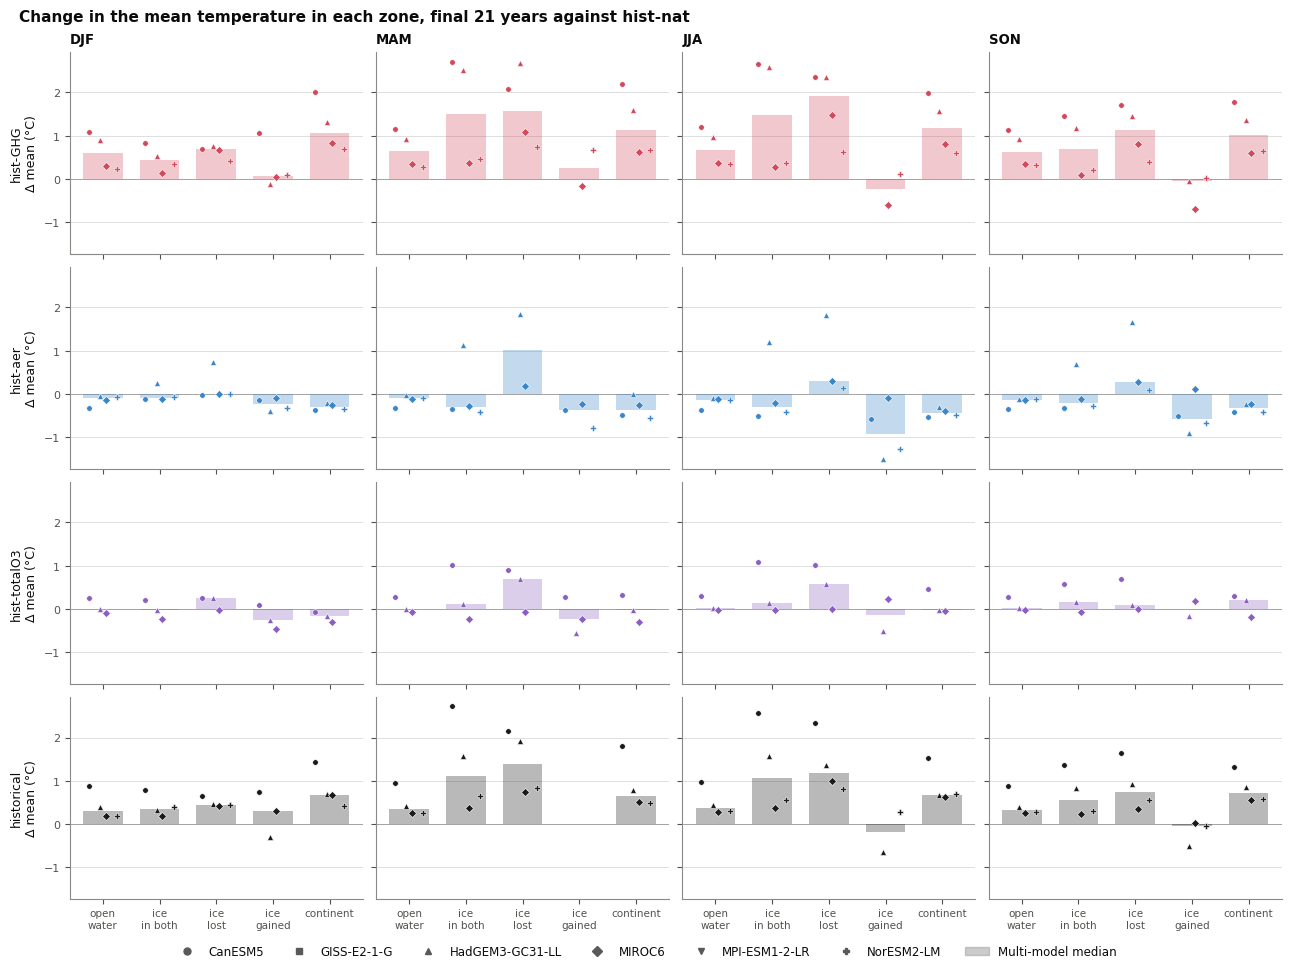

In [42]:
fig, axes = sip.zone_changes(tas_zone_means_ds['mean'], 'Δ mean (°C)', experiments=EXPERIMENTS, seasons=SEASONS,
                             title=f'Change in the mean temperature in each zone, final {WINDOW} years against hist-nat')

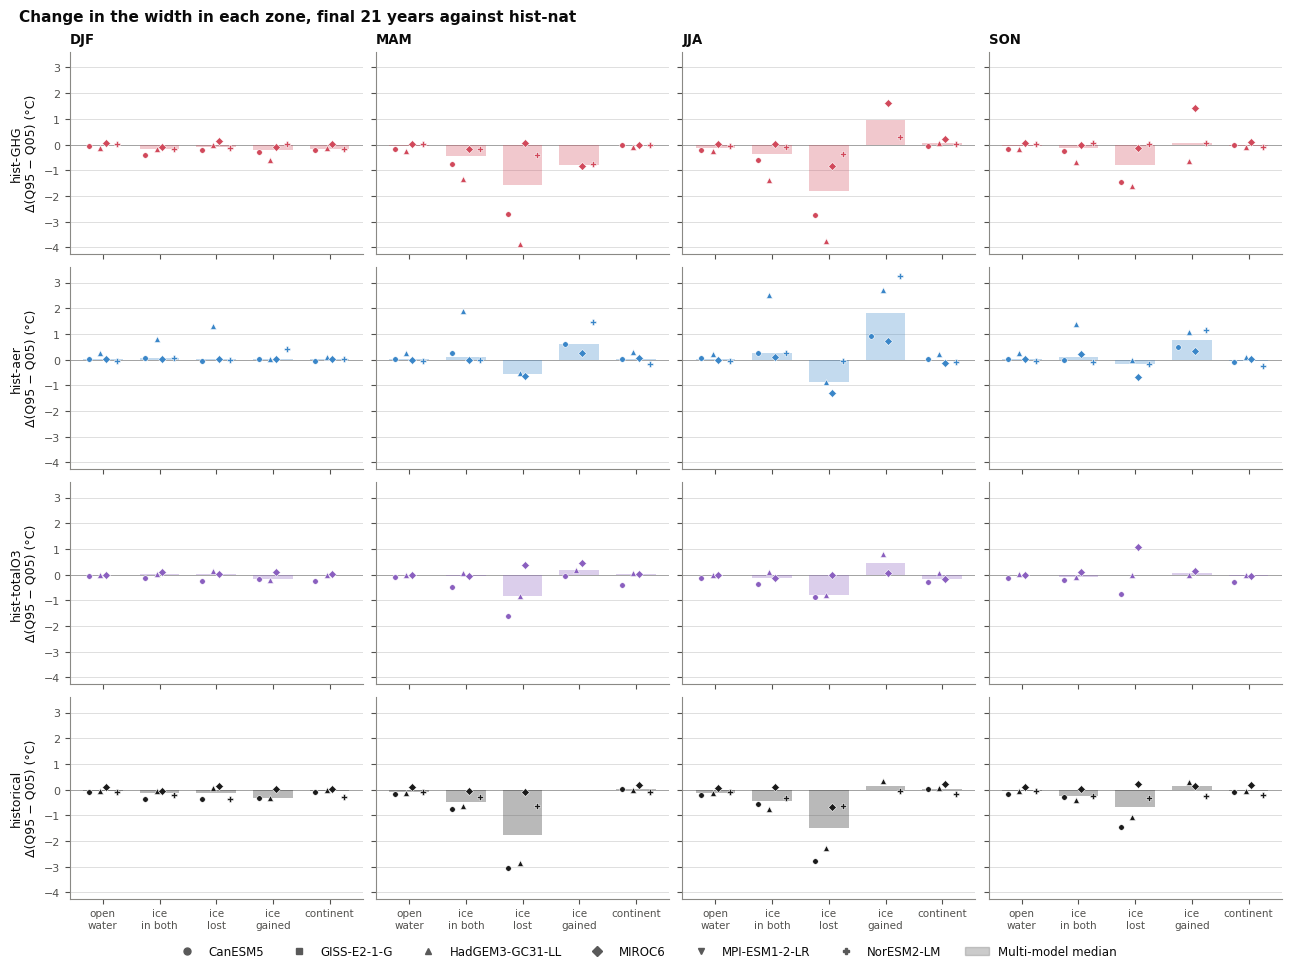

In [43]:
fig, axes = sip.zone_changes(tas_zone_means_ds['width'], 'Δ(Q95 − Q05) (°C)', experiments=EXPERIMENTS, seasons=SEASONS,
                             title=f'Change in the width in each zone, final {WINDOW} years against hist-nat')

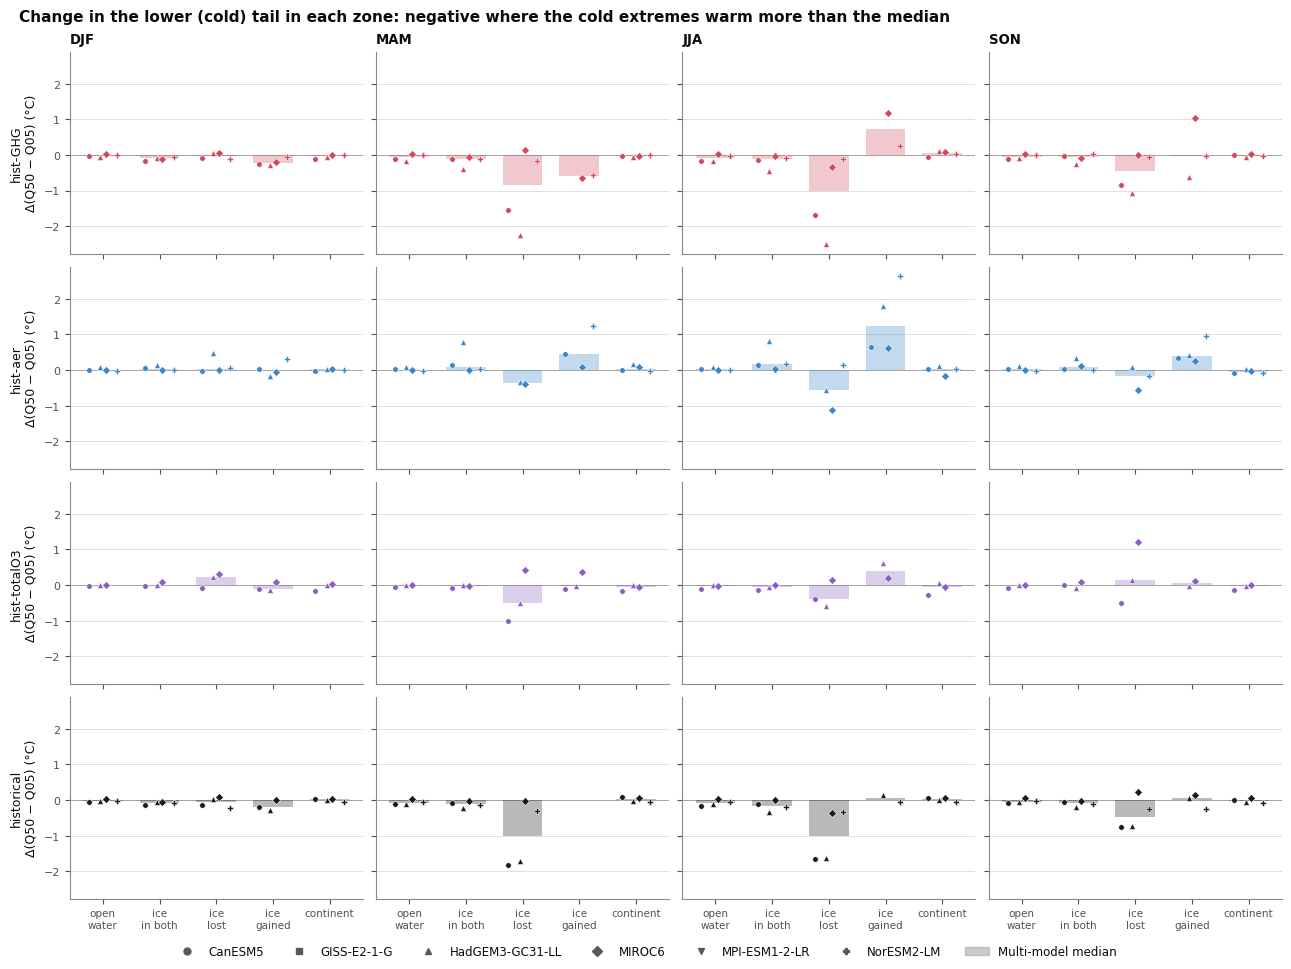

In [44]:
fig, axes = sip.zone_changes(tas_zone_means_ds['lower tail'], 'Δ(Q50 − Q05) (°C)', experiments=EXPERIMENTS,
                             seasons=SEASONS,
                             title='Change in the lower (cold) tail in each zone: negative where the cold extremes '
                                   'warm more than the median')

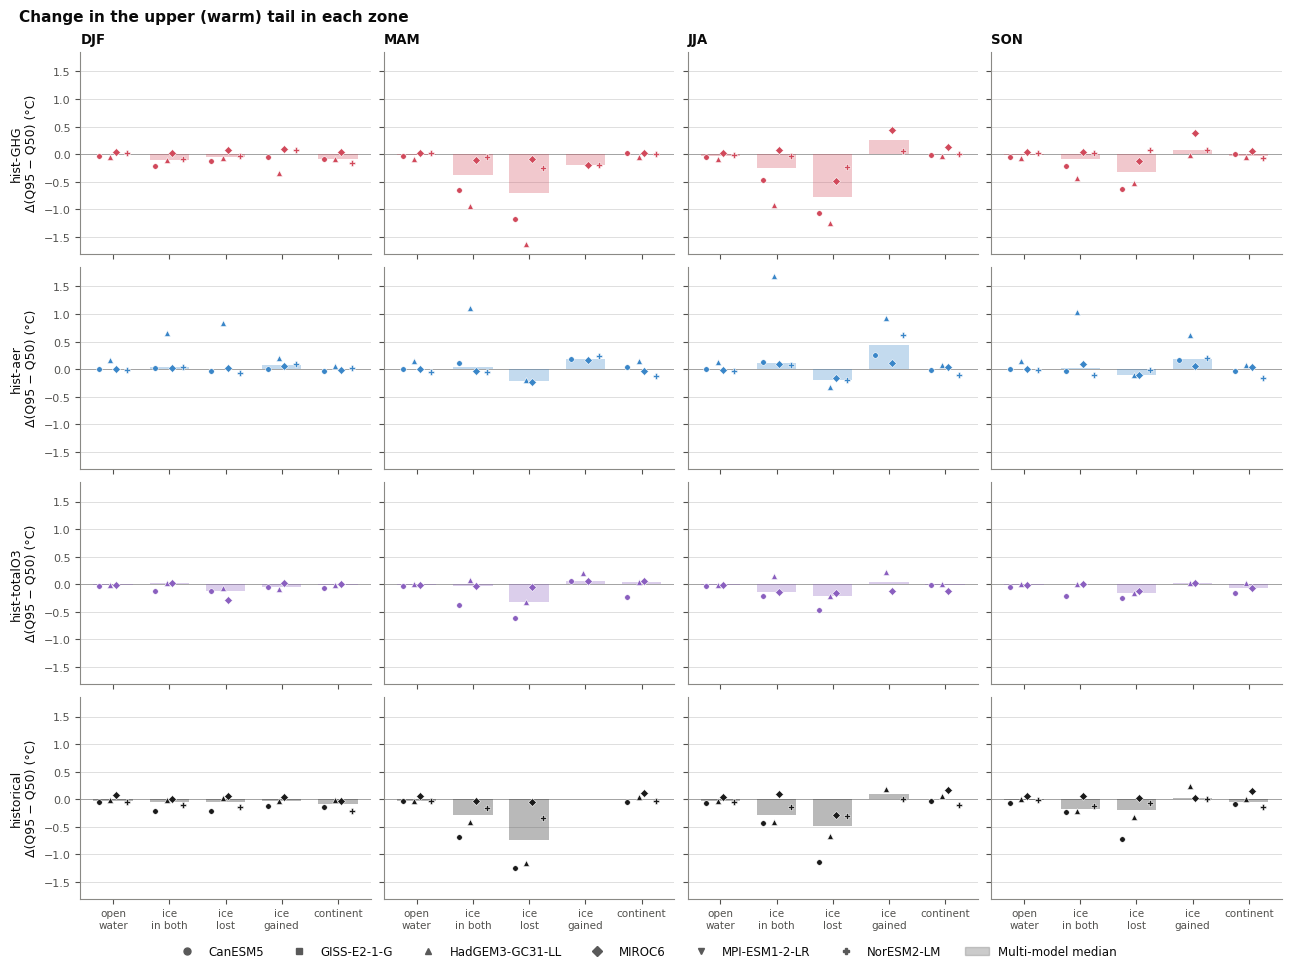

In [45]:
fig, axes = sip.zone_changes(tas_zone_means_ds['upper tail'], 'Δ(Q95 − Q50) (°C)', experiments=EXPERIMENTS,
                             seasons=SEASONS, title='Change in the upper (warm) tail in each zone')

### Extent change against temperature change

One point per model and forcing: the change in extent against the change in the mean, and in the width, averaged over the cells with ice in hist-nat. If losing ice drives them, more loss (further left) goes with more warming and more narrowing.

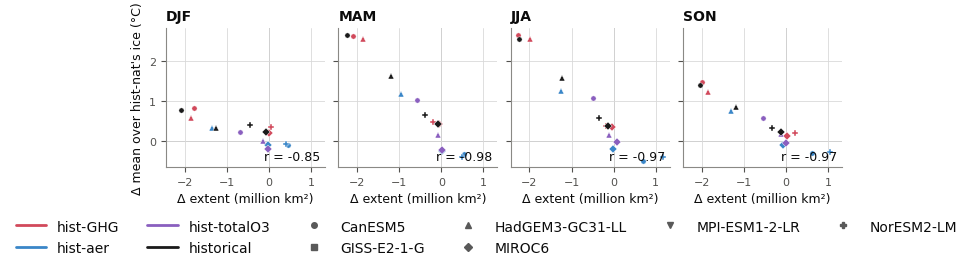

In [46]:
panels = paper_panels.scatter_by_season(extent_change_ds['extent_change'], ice_region_change_ds['mean'],
                                        'Δ extent (million km²)', "Δ mean over hist-nat's ice (°C)",
                                        experiments=EXPERIMENTS, columns=SEASONS, style=fr.NOTEBOOK)

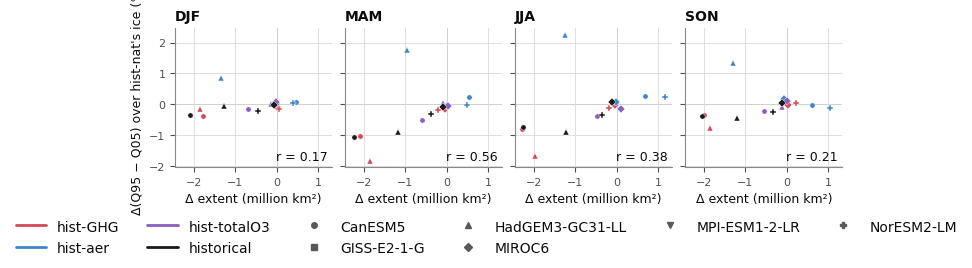

In [47]:
panels = paper_panels.scatter_by_season(extent_change_ds['extent_change'], ice_region_change_ds['width'],
                                        'Δ extent (million km²)', "Δ(Q95 − Q05) over hist-nat's ice (°C)",
                                        experiments=EXPERIMENTS, columns=SEASONS, style=fr.NOTEBOOK)

### Year-to-year correlation

Strongly negative where a season with more ice is a colder season: that is where the ice sets the year-to-year variability of the temperature. ERA5's in the last row.

In [ ]:
#(t): The correlations, every model and ERA5
coupling_rows_da = xr.open_zarr(RESULTS_DIR / 'ice_tas_correlation.zarr')['correlation'].load()
coupling_rows_da

In [ ]:
#(t): Each row's own edge: hist-nat's final years for the models, ERA5's 1979-2013, in the rows' order
coupling_ice_da = xr.concat([ice_climatology_da.sel(experiment='hist-nat', drop=True),
                             era5_climatology_da.expand_dims(model=['ERA5'])], dim='model')
coupling_ice_da = coupling_ice_da.sel(model=coupling_rows_da['model'])

In [ ]:
#(t): Every model and ERA5 (rows) and season (columns): the correlation, with each row's own edge
n_rows = coupling_rows_da.sizes['model']
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=n_rows, n_cols=len(SEASONS), n_colorbars=1))
axes, cbar_axes = antarctica.map_axes(fig, n_rows=n_rows, n_cols=len(SEASONS), n_colorbars=1)

antarctica.heatmaps_of_antarctica(coupling_rows_da.sel(season=SEASONS), 'model', 'season', axes=axes, cax=cbar_axes[0],
                                  **correlation_colours)
antarctica.ice_edges(coupling_ice_da.sel(season=SEASONS), 'model', 'season', axes=axes)

antarctica.label_columns(axes, SEASONS)
antarctica.label_rows(axes, coupling_rows_da['model'].values)
fig.suptitle('Year to year, how the sea ice and the temperature move together: hist-nat, and ERA5');